In [1]:
import cv2
from PIL import Image
import numpy as np
import mediapipe as mp
from mediapipe import solutions
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from mediapipe.framework.formats import landmark_pb2

def draw_landmarks_on_image(rgb_image, detection_result):
    pose_landmarks_list = detection_result.pose_landmarks
    annotated_image = np.copy(rgb_image)

    # Loop through the detected poses to visualize.
    for idx in range(len(pose_landmarks_list)):
        pose_landmarks = pose_landmarks_list[idx]

        # Draw the pose landmarks.
        pose_landmarks_proto = landmark_pb2.NormalizedLandmarkList()
        pose_landmarks_proto.landmark.extend([
          landmark_pb2.NormalizedLandmark(x=landmark.x, y=landmark.y, z=landmark.z) for landmark in pose_landmarks
        ])
        solutions.drawing_utils.draw_landmarks(
            annotated_image,
            pose_landmarks_proto,
            solutions.pose.POSE_CONNECTIONS,
            solutions.drawing_styles.get_default_pose_landmarks_style())
    return annotated_image



## Image

In [2]:
import mediapipe as mp

BaseOptions = mp.tasks.BaseOptions
PoseLandmarker = mp.tasks.vision.PoseLandmarker
PoseLandmarkerOptions = mp.tasks.vision.PoseLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

model_path = 'pose_landmarker_full.task'
options = PoseLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=model_path),
    running_mode=VisionRunningMode.IMAGE)


# Load the input image from an image file.
mp_image = mp.Image.create_from_file('test.png')

with PoseLandmarker.create_from_options(options) as landmarker:
    # The landmarker is initialized. Use it here.
    pose_landmarker_result = landmarker.detect(mp_image)
    
    annotated_image = draw_landmarks_on_image(mp_image.numpy_view()[:,:,:3], pose_landmarker_result)
    im = Image.fromarray(annotated_image)
    im.show()

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


## Direct Stream Image

In [ ]:
import mediapipe as mp
import numpy as np
import cv2 as cv

cap = cv.VideoCapture(0)

if not cap.isOpened():
    print("Cannot open camera")
    exit()
    

BaseOptions = mp.tasks.BaseOptions
PoseLandmarker = mp.tasks.vision.PoseLandmarker
PoseLandmarkerOptions = mp.tasks.vision.PoseLandmarkerOptions
PoseLandmarkerResult = mp.tasks.vision.PoseLandmarkerResult
VisionRunningMode = mp.tasks.vision.RunningMode

model_path = 'pose_landmarker_full.task'
options = PoseLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=model_path),
    running_mode=VisionRunningMode.IMAGE)

cap = cv.VideoCapture(0)

if not cap.isOpened():
    print("Cannot open camera")
    exit()
    
landmarker = PoseLandmarker.create_from_options(options)
    
while True:
    ret, frame = cap.read()
    if not ret:
        print("Can't receive frame. Exiting ...")
        break
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)
    pose_landmarker_result = landmarker.detect(mp_image)
    
    
    if len(pose_landmarker_result.pose_landmarks) <0 or not pose_landmarker_result.pose_landmarks:
        continue
    
    pose_landmarks_list = pose_landmarker_result.pose_landmarks[0]
    
    right_wrist = pose_landmarks_list[16]
    right_pinky = pose_landmarks_list[18]
    right_index = pose_landmarks_list[20]
    
    image_shape = mp_image.numpy_view()[:,:,:3].shape
    
#     print(right_wrist)
#     print()
#     print(right_pinky)
#     print()
#     print(right_index)

#     print("----------")
#     print(right_wrist.x)
#     print(right_wrist.y)
#     print(image_shape)


    if right_wrist.presence < 0.6:
        print("No hay brazo presente")
    else:
        pos_x, pos_y = round(image_shape[1]*right_wrist.x,0), round(image_shape[0]*right_wrist.y,0)
        print("Posicion de la mano:",  pos_x, pos_y)

    annotated_image = draw_landmarks_on_image(mp_image.numpy_view()[:,:,:3], pose_landmarker_result)
    
    cv.imshow('frame', annotated_image)
    if cv.waitKey(1) == ord('q'):
        break

#     cv2.imwrite('filename.jpeg', annotated_image)

## Stream

In [ ]:
# import mediapipe as mp
# import numpy as np
# import cv2 as cv

# cap = cv.VideoCapture(0)

# if not cap.isOpened():
#     print("Cannot open camera")
#     exit()
    

# BaseOptions = mp.tasks.BaseOptions
# PoseLandmarker = mp.tasks.vision.PoseLandmarker
# PoseLandmarkerOptions = mp.tasks.vision.PoseLandmarkerOptions
# PoseLandmarkerResult = mp.tasks.vision.PoseLandmarkerResult
# VisionRunningMode = mp.tasks.vision.RunningMode

# # Create a pose landmarker instance with the live stream mode:
# def show_result(result: PoseLandmarkerResult, output_image: mp.Image, timestamp_ms: int):
#     # print('pose landmarker result: {}'.format(result))
    
#     annotated_image = draw_landmarks_on_image(output_image.numpy_view()[:,:,:3], result)
#     cv.imshow('frame', annotated_image)
# #     if cv.waitKey(1) == ord('q'):
# #         raise Exception("Error!!")


# options = PoseLandmarkerOptions(
#     base_options=BaseOptions(model_asset_path=model_path),
#     running_mode=VisionRunningMode.LIVE_STREAM,
#     result_callback=show_result)

# frame_timestamp_ms = 0
# with PoseLandmarker.create_from_options(options) as landmarker:
    
#     while True:
#         frame_timestamp_ms += 1
#         ret, frame = cap.read()
#         if not ret:
#             print("Can't receive frame. Exiting ...")
#             break
            
#         # Our operations on the frame come here
#         # gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
#         # Display the resulting frame
#         mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)
#         pose_landmarker_result = landmarker.detect(mp_image)
        
    
        
#         landmarker.detect_async(mp_image, frame_timestamp_ms)

https://developers.google.com/mediapipe/solutions/vision/pose_landmarker/python#live-stream_1
https://developers.google.com/mediapipe/solutions/vision/pose_landmarker/python#handle_and_display_results
https://developers.google.com/mediapipe/solutions/vision/pose_landmarker/index#models

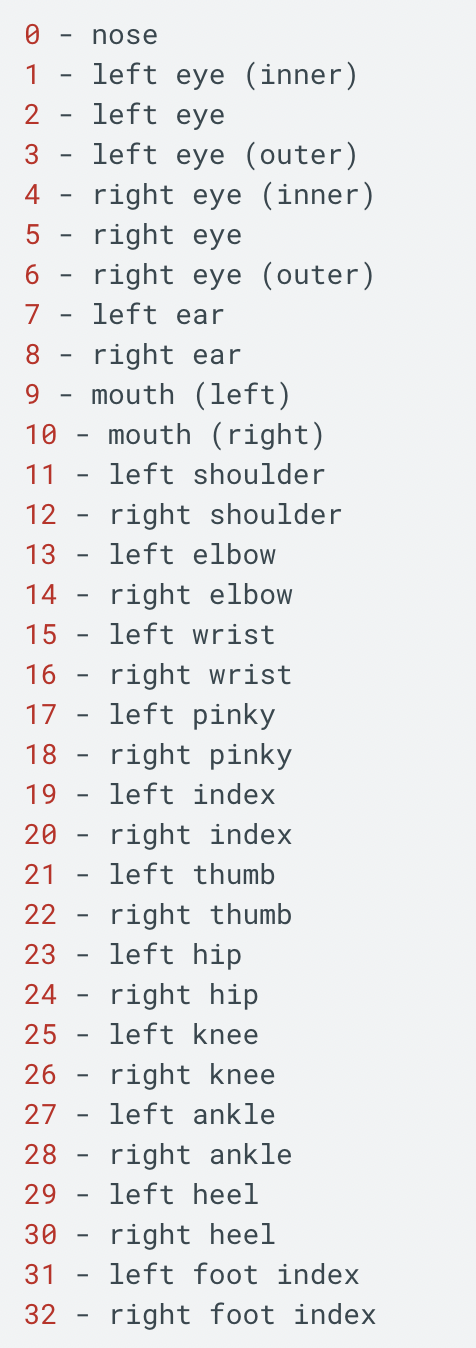

## Hand Landmark recog

In [3]:

from mediapipe import solutions
from mediapipe.framework.formats import landmark_pb2
import numpy as np

MARGIN = 10  # pixels
FONT_SIZE = 1
FONT_THICKNESS = 1
HANDEDNESS_TEXT_COLOR = (88, 205, 54) # vibrant green

def draw_landmarks_on_image_hand(rgb_image, detection_result):
    hand_landmarks_list = detection_result.hand_landmarks
    handedness_list = detection_result.handedness
    annotated_image = np.copy(rgb_image)

    # Loop through the detected hands to visualize.
    for idx in range(len(hand_landmarks_list)):
        hand_landmarks = hand_landmarks_list[idx]
        handedness = handedness_list[idx]

        # Draw the hand landmarks.
        hand_landmarks_proto = landmark_pb2.NormalizedLandmarkList()
        hand_landmarks_proto.landmark.extend([
          landmark_pb2.NormalizedLandmark(x=landmark.x, y=landmark.y, z=landmark.z) for landmark in hand_landmarks
        ])
        solutions.drawing_utils.draw_landmarks(
          annotated_image,
          hand_landmarks_proto,
          solutions.hands.HAND_CONNECTIONS,
          solutions.drawing_styles.get_default_hand_landmarks_style(),
          solutions.drawing_styles.get_default_hand_connections_style())

        # Get the top left corner of the detected hand's bounding box.
        height, width, _ = annotated_image.shape
        x_coordinates = [landmark.x for landmark in hand_landmarks]
        y_coordinates = [landmark.y for landmark in hand_landmarks]
        text_x = int(min(x_coordinates) * width)
        text_y = int(min(y_coordinates) * height) - MARGIN

        # Draw handedness (left or right hand) on the image.
        cv2.putText(annotated_image, f"{handedness[0].category_name}",
                    (text_x, text_y), cv2.FONT_HERSHEY_DUPLEX,
                    FONT_SIZE, HANDEDNESS_TEXT_COLOR, FONT_THICKNESS, cv2.LINE_AA)

    return annotated_image

In [5]:
import mediapipe as mp
import numpy as np
import cv2 as cv

cap = cv.VideoCapture(0)

if not cap.isOpened():
    print("Cannot open camera")
    exit()
    

BaseOptions = mp.tasks.BaseOptions
HandLandmarker = mp.tasks.vision.HandLandmarker
HandLandmarkerOptions = mp.tasks.vision.HandLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

model_path = 'hand_landmarker.task'
# Create a hand landmarker instance with the image mode:
options = HandLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=model_path),
    running_mode=VisionRunningMode.IMAGE)


cap = cv.VideoCapture(0)

if not cap.isOpened():
    print("Cannot open camera")
    exit()
    
landmarker = HandLandmarker.create_from_options(options)
    
while True:
    ret, frame = cap.read()
    if not ret:
        print("Can't receive frame. Exiting ...")
        break
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)
    
    
    hand_landmarker_result = landmarker.detect(mp_image)
    

    hand_landmarker_result
    annotated_image = draw_landmarks_on_image_hand(mp_image.numpy_view()[:,:,:3], hand_landmarker_result)
    
    cv.imshow('frame', annotated_image)
    if cv.waitKey(1) == ord('q'):
        break

#     cv2.imwrite('filename.jpeg', annotated_image)

## Hand Gesture Recog

In [6]:
from matplotlib import pyplot as plt
import mediapipe as mp
from mediapipe.framework.formats import landmark_pb2

plt.rcParams.update({
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.spines.left': False,
    'axes.spines.bottom': False,
    'xtick.labelbottom': False,
    'xtick.bottom': False,
    'ytick.labelleft': False,
    'ytick.left': False,
    'xtick.labeltop': False,
    'xtick.top': False,
    'ytick.labelright': False,
    'ytick.right': False
})

mp_hands = mp.solutions.hands
mp_drawing = mp.solutions.drawing_utils
mp_drawing_styles = mp.solutions.drawing_styles


def display_one_image(image, title, subplot, titlesize=16):
    """Displays one image along with the predicted category name and score."""
    plt.subplot(*subplot)
    plt.imshow(image)
    if len(title) > 0:
        plt.title(title, fontsize=int(titlesize), color='black', fontdict={'verticalalignment':'center'}, pad=int(titlesize/1.5))
    return (subplot[0], subplot[1], subplot[2]+1)


def display_batch_of_images_with_gestures_and_hand_landmarks(images, results):
    """Displays a batch of images with the gesture category and its score along with the hand landmarks."""
    # Images and labels.
    images = [image.numpy_view() for image in images]
    gestures = [top_gesture for (top_gesture, _) in results]
    multi_hand_landmarks_list = [multi_hand_landmarks for (_, multi_hand_landmarks) in results]

    # Auto-squaring: this will drop data that does not fit into square or square-ish rectangle.
    rows = int(math.sqrt(len(images)))
    cols = len(images) // rows

    # Size and spacing.
    FIGSIZE = 13.0
    SPACING = 0.1
    subplot=(rows,cols, 1)
    if rows < cols:
        plt.figure(figsize=(FIGSIZE,FIGSIZE/cols*rows))
    else:
        plt.figure(figsize=(FIGSIZE/rows*cols,FIGSIZE))

    # Display gestures and hand landmarks.
    for i, (image, gestures) in enumerate(zip(images[:rows*cols], gestures[:rows*cols])):
        title = f"{gestures.category_name} ({gestures.score:.2f})"
        dynamic_titlesize = FIGSIZE*SPACING/max(rows,cols) * 40 + 3
        annotated_image = image.copy()

        for hand_landmarks in multi_hand_landmarks_list[i]:
          hand_landmarks_proto = landmark_pb2.NormalizedLandmarkList()
          hand_landmarks_proto.landmark.extend([
            landmark_pb2.NormalizedLandmark(x=landmark.x, y=landmark.y, z=landmark.z) for landmark in hand_landmarks
          ])

          mp_drawing.draw_landmarks(
            annotated_image,
            hand_landmarks_proto,
            mp_hands.HAND_CONNECTIONS,
            mp_drawing_styles.get_default_hand_landmarks_style(),
            mp_drawing_styles.get_default_hand_connections_style())

        subplot = display_one_image(annotated_image, title, subplot, titlesize=dynamic_titlesize)

    # Layout.
    plt.tight_layout()
    plt.subplots_adjust(wspace=SPACING, hspace=SPACING)
    plt.show()

In [20]:
BaseOptions = mp.tasks.BaseOptions
GestureRecognizer = mp.tasks.vision.GestureRecognizer
GestureRecognizerOptions = mp.tasks.vision.GestureRecognizerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

model_path = 'gesture_recognizer.task'
# Create a gesture recognizer instance with the image mode:
options = GestureRecognizerOptions(
    base_options=BaseOptions(model_asset_path=model_path),
    running_mode=VisionRunningMode.IMAGE)


cap = cv.VideoCapture(0)

if not cap.isOpened():
    print("Cannot open camera")
    exit()
    
recognizer = GestureRecognizer.create_from_options(options)
    
while True:
    ret, frame = cap.read()
    if not ret:
        print("Can't receive frame. Exiting ...")
        break
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame) 
    
    recognition_result = recognizer.recognize(mp_image)

    #print(recognition_result)
    if len(recognition_result.gestures) > 0:
        top_gesture = recognition_result.gestures[0][0]
        

        print(top_gesture)

    hand_landmarks = recognition_result.hand_landmarks
    annotated_image = draw_landmarks_on_image_hand(mp_image.numpy_view()[:,:,:3], hand_landmarker_result)

    cv.imshow('frame', annotated_image)
    if cv.waitKey(1) == ord('q'):
        break

#     cv2.imwrite('filename.jpeg', annotated_image)

W0000 00:00:1696010124.069370       1 gesture_recognizer_graph.cc:129] Hand Gesture Recognizer contains CPU only ops. Sets HandGestureRecognizerGraph acceleration to Xnnpack.
I0000 00:00:1696010124.071718       1 hand_gesture_recognizer_graph.cc:250] Custom gesture classifier is not defined.


RuntimeError: uint8 image data should be one of the GRAY8, SRGB, and SRGBA MediaPipe image formats.